# 论文表格对账本 — CCS（Complex Count Sketch）

本 notebook 把论文四张表格（Table 2-5）与两张图（fig_sweep / fig_regime）的
实验代码集中在一处，**先展示脚本源码，再原样运行**，运行输出即论文值
facsimile：每格并列"复现值 / 发表值"，命中标注 `*`、偏离标注 `!`，可逐格
与论文核对。

- 脚本本体在 `../tables/`，本 notebook 通过 `inspect.getsource` 展示并调用，
  不会与脚本产生漂移。
- 所有数字均为 **2026-10-23 在 py311 / numpy 1.26.4 下实测**；归档生产日志
  捆绑在 `../results/`。
- 复现基线协议即论文协议（Table 2: 5 轮；Table 3: 1000 runs；Table 4:
  T=100；Table 5: T=24）。全部跑完约 75 分钟；如只想看代码，不必执行。

**阅读顺序**：环境 → Table 2 → Table 3 → Table 4 → Table 5 → 图 → 总结。


In [1]:
import os
import sys

# Locate the artifact root (this notebook lives in Complex_Count_Sketch/notebooks/).
# Walk upwards from the cwd so the notebook is portable to any checkout.
_here = os.path.abspath(os.getcwd())
ART = None
for _up in range(4):
    _cand = os.path.abspath(os.path.join(_here, *([".."] * _up)))
    if os.path.exists(os.path.join(_cand, "ccs.py")):
        ART = _cand
        break
if ART is None:
    raise RuntimeError("artifact root not found (no ccs.py in cwd or "
                       "its first three parents); run this notebook from "
                       "Complex_Count_Sketch/notebooks/")
sys.path.insert(0, ART)
os.chdir(ART)

import platform
import numpy as np
import ccs
import loaders
print("artifact :", ART)
print("python   :", platform.python_version())
print("numpy    :", np.__version__)
print("data dir :", loaders.DATA)

artifact : <repo root>
python   : 3.11.13
numpy    : 1.26.4
data dir : <repo root>/data


## Table 2 — 合成 + 真实数据上的 $F_p$ 估计（`table:lpnorm`）

协议：4 个合成分布（uniform / zipf1.1 / zipf1.5 / mix，$D=10^4$、$N=10^7$）
与三大真实数据集（MovieLens 25M、Airlines 10M、Kasandr merge 列）上的
$p=3,4,5$；每数据集 5 轮，报告 running mean 的相对误差；CCS 用与 C++ 驱动
完全一致的 MurmurHash32 原始行字符串视图。

**取数口径**：论文 Table 2 的相对误差由 C++ 驱动以 6 位有效数字打印的估计值
计算（本包按同一约定复现）；p=4/p=5 合成与全部真实数据集的归档日志已捆绑在
`results/table2/`，可逐位复核（见 `table2_archive_audit.py`）。**AMS 列
不可复现**：C++ 管线用 `std::random_device` 抽位置种子，论文表的 AMS 列
因此不参与逐格对账（CCS 列不受影响）。

预期结果：42 个 CCS 格全部命中论文值（`*`），加粗 pattern 与论文一致。


In [2]:
import inspect
import tables.table2_lpnorm as t2
print(inspect.getsource(t2))


r"""tables/table2_lpnorm.py -- reproduce paper Table 2 (table:lpnorm).

F_p estimation error of AMS vs CCS on the four synthetic Lp columns and the
three real datasets, p = 3, 4, 5.

Provenance (see README "Table 2" for the full audit)
----------------------------------------------------
The paper's numbers come from the C++ drivers in cpp/ (main.cpp, ML.cpp,
Airlines.cpp, kasandr.cpp), each run for 5 rounds with hash_seed = round and
a running mean of the per-round estimates.  This script re-runs the SAME
protocol through the bit-exact Python port of those drivers (ccs.py:

  * cpp_ccs_estimate  -- ComplexCountSketch.estimate_lp(): width
    ceil(2^p/eps^2), depth ceil(ln(4/gam)), MurmurHash32 bucket/root hashes,
    C^p by repeated complex multiplication, median over rows.
  * cpp_ams_estimate  -- AMS positional sample-count estimator.

Reproduction status, verified cell by cell:
  * CCS column: reproduced EXACTLY for every cell of the paper's table.
  * AMS column: the C++ draws its

In [3]:
t2.main()


# Table 2 (table:lpnorm): F_p relative error, AMS vs CCS, 5 rounds, running mean


# relative errors use the 6-significant-digit rounded estimates (the C++ printing convention the paper's table was built from)


== uniform ==


  [uniform] uniform.dat: D=10000  p=3: ams=1.42E-02 ccs=5.81E-02  p=4: ams=1.65E-02 ccs=2.55E-01  p=5: ams=1.67E-02 ccs=1.44E-01


== zipf1.1 ==


  [zipf1.1] zipf1.1.dat: D=2817204  p=3: ams=2.82E-02 ccs=1.52E-04  p=4: ams=3.25E-02 ccs=6.18E-05  p=5: ams=2.00E-02 ccs=4.43E-04


... (35 outputs left out)

         MovieLens | 1.28E-01,8.77E-03! / 1.79E-01,3.28E-02    8.06E-03,5.48E-03* / 8.06E-03,5.48E-03 | 2.37E-01,7.70E-03! / 1.08E-01,2.73E-02    6.36E-03,1.77E-04* / 6.36E-03,1.77E-04 | 2.81E-01,1.45E-02! / 2.91E-01,1.43E-02    5.80E-03,5.31E-04* / 5.80E-03,5.31E-04


          Airlines | 1.17E-02,9.36E-03! / 1.58E-02,1.70E-02    7.28E-03,2.33E-04* / 7.28E-03,2.33E-04 | 1.90E-02,1.30E-02! / 1.53E-02,1.24E-02    2.74E-03,5.60E-05* / 2.74E-03,5.60E-05 | 2.79E-02,1.83E-02! / 3.81E-02,2.67E-02    1.49E-03,1.75E-05* / 1.49E-03,1.75E-05


           Kasandr | 3.20E-02,1.97E-02! / 3.37E-02,1.16E-02    8.71E-03,3.10E-03* / 8.71E-03,3.10E-03 | 5.06E-02,3.75E-02! / 6.99E-02,1.87E-02    3.41E-02,4.30E-04* / 3.41E-02,4.30E-04 | 5.86E-02,5.21E-02! / 4.35E-02,2.77E-02    5.08E-02,1.79E-04* / 5.08E-02,1.79E-04



# paper Table 2 facsimile (reproduced values; bold = best of AMS/CCS per row/order)
#          dataset     agg | p=3 AMS CCS | p=4 AMS CCS | p=5 AMS CCS
           uniform         | **1.42E-02** 5.81E-02 | **1.65E-02** 2.55E-01 | **1.67E-02** 1.44E-01
           zipf1.1         | 2.82E-02 **1.52E-04** | 3.25E-02 **6.18E-05** | 2.00E-02 **4.43E-04**
           zipf1.5         | 2.33E-02 **4.22E-06** | 2.22E-02 **8.77E-07** | 1.79E-02 **1.95E-05**
   uniform+zipf1.1         | 2.34E-02 **3.34E-06** | 2.22E-02 **1.64E-06** | 1.79E-02 **2.17E-05**
         MovieLens    Mean | 1.28E-01 **8.06E-03** | 2.37E-01 **6.36E-03** | 2.81E-01 **5.80E-03**
         MovieLens  Median | 8.77E-03 **5.48E-03** | 7.70E-03 **1.77E-04** | 1.45E-02 **5.31E-04**
          Airlines    Mean | 1.17E-02 **7.28E-03** | 1.90E-02 **2.74E-03** | 2.79E-02 **1.49E-03**
          Airlines  Median | 9.36E-03 **2.33E-04** | 1.30E-02 **5.60E-05** | 1.83E-02 **1.75E-05**
           Kasandr    Mean | 3.20E-02 **8.71E-03** | 5

## Table 3 — T-MCCS vs 原始 CCS（`table:tmccs`）

协议：$\alpha\in\{0,0.5,0.8,1.0,1.1,1.5,2.0\}$ 的截尾 Zipf（$D=10^3$、
$N=10^5$），$w=256$、$d=64$、**1000 runs**，$p=3,4,5$；四个估计量
CCS(plain median) / T-MCCS / Fixed_20 / Rand_20 的绝对相对误差，附
Wilson 区间与符号检验胜率。

**已知偏差（论文侧）**：Fixed20 ($p=3,\alpha=1.0$) 论文值 2.00E-03，
归档日志为 2.454e-03 —— 本包复现归档值，疑为论文转录笔误（该行加粗结论
不受影响）。其余 83/84 格与归档逐位一致。


In [4]:
import inspect
import tables.table3_tmccs as t3
print(inspect.getsource(t3))


r"""tables/table3_tmccs.py -- reproduce paper Table 3 (tab:tmccs).

Original CCS estimator (plain median) vs T-MCCS and the two controls
Fixed_20 / Rand_20, absolute relative error; alpha is the Zipf skewness;
w=256, d=64, 1000 runs, p=3,4,5.

Faithful port of the archived producer chain
    paper_code/experiments/exp3_tmccs_stats.py        (plain / T-MCCS columns)
    paper_code/python/03_tmccs_estimators.py detail   (Fixed_20 / Rand_20 columns)
with the RNG draw order and seed bases preserved, so the output matches the
archived logs bit-for-bit (see results/exp3_tmccs_stats.expected.txt and
results/tmccs_detail.txt).

Usage:
    python3 tables/table3_tmccs.py            # paper protocol: 1000 runs
    python3 tables/table3_tmccs.py 200        # smoke: 200 runs
"""
import os
import sys

import numpy as np

sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
import ccs

D, N, W, DEPTH = 1000, 100_000, 256, 64
def _trials_from_argv(default=1000):
    """Paper

In [5]:
t3.main()


# Table 3 (tab:tmccs): absolute relative error, w=256, d=64, 1000 runs, D=1000, N=100000
#  alpha | p=3: CCS / T-MCCS / Fixed20 / Rand20 | p=4: CCS / T-MCCS / Fixed20 / Rand20 | p=5: CCS / T-MCCS / Fixed20 / Rand20
--- p=3 ---


a=0.0: CCS=3.75E-02 T-MCCS=3.84E-02 Fixed20=4.39E-02 Rand20=4.20E-02  G/A=1.024 wins=257/1000 wilson=[0.231,0.285]


a=0.5: CCS=2.73E-02 T-MCCS=2.68E-02 Fixed20=2.66E-02 Rand20=2.94E-02  G/A=0.983 wins=378/1000 wilson=[0.348,0.408]


a=0.8: CCS=9.18E-03 T-MCCS=7.44E-03 Fixed20=6.91E-03 Rand20=9.68E-03  G/A=0.810 wins=727/1000 wilson=[0.699,0.754]


a=1.0: CCS=3.63E-03 T-MCCS=2.63E-03 Fixed20=2.45E-03 Rand20=3.79E-03  G/A=0.723 wins=759/1000 wilson=[0.732,0.784]


a=1.1: CCS=2.22E-03 T-MCCS=1.52E-03 Fixed20=1.41E-03 Rand20=2.35E-03  G/A=0.684 wins=781/1000 wilson=[0.754,0.806]


... (15 outputs left out)

a=1.1: CCS=1.67E-03 T-MCCS=1.54E-03 Fixed20=1.49E-03 Rand20=1.84E-03  G/A=0.920 wins=511/1000 wilson=[0.480,0.542]


a=1.5: CCS=1.73E-04 T-MCCS=1.58E-04 Fixed20=1.46E-04 Rand20=2.01E-04  G/A=0.910 wins=522/1000 wilson=[0.491,0.553]


a=2.0: CCS=6.20E-06 T-MCCS=4.64E-06 Fixed20=4.31E-06 Rand20=7.24E-06  G/A=0.748 wins=531/1000 wilson=[0.500,0.562]



# paper Table 3 facsimile (bold = best of the four per row/order)
# alpha | p=3: CCS T-MCCS Fixed20 Rand20 | p=4: CCS T-MCCS Fixed20 Rand20 | p=5: CCS T-MCCS Fixed20 Rand20
0.0 | **3.75E-02** 3.84E-02 4.39E-02 4.20E-02 | **1.35E-01** 1.39E-01 1.58E-01 1.49E-01 | **5.83E-01** 5.93E-01 6.11E-01 6.60E-01
0.5 | 2.73E-02 2.68E-02 **2.66E-02** 2.94E-02 | 4.80E-02 **4.66E-02** 4.83E-02 5.08E-02 | **7.16E-02** 7.25E-02 8.10E-02 7.29E-02
0.8 | 9.18E-03 7.44E-03 **6.91E-03** 9.68E-03 | 8.12E-03 7.03E-03 **6.97E-03** 8.75E-03 | 9.02E-03 8.96E-03 **8.77E-03** 1.01E-02
1.0 | 3.63E-03 2.63E-03 **2.45E-03** 3.79E-03 | 2.26E-03 **1.97E-03** 2.00E-03 2.48E-03 | 2.90E-03 2.72E-03 **2.64E-03** 3.20E-03
1.1 | 2.22E-03 1.52E-03 **1.41E-03** 2.35E-03 | 1.15E-03 **1.02E-03** 1.05E-03 1.28E-03 | 1.67E-03 1.54E-03 **1.49E-03** 1.84E-03
1.5 | 3.06E-04 1.76E-04 **1.56E-04** 3.21E-04 | 8.83E-05 **7.52E-05** 7.97E-05 9.71E-05 | 1.73E-04 1.58E-04 **1.46E-04** 2.01E-04
2.0 | 2.29E-05 1.06E-05 **9.24E-06** 2.36E-05 

## Table 4 — p-star join 的 T-MCCS 评测（`table:pstar`）

协议：$p=3$、$w=256$、$d=64$、$N=10^7$/列、**T=100 个哈希族**（seed 7919）；
6 个列组合（均匀×均匀×均匀 → Zipf1.5³）。CCS / T-MCCS / G-A 列来自
`rev_pstar.py` 协议（每组合一个 rng，Rand20 的排列抽取保持流对齐）；
Per-edge / Shared-sign 列来自 exp9 协议（种子 8100+t / 8200+t，T=100）。

**移植质量记录**：本包第一版 `table4_pstar.py` 的内联复数乘法曾把虚部写成
`pr*ci + pi*ci`（正确为 `pr*ci + pi*cr`），被归档交叉核对当场抓住；修复后
与原始生产者在 py311 下逐位一致。这也是本对账本存在的意义——**每个数字
都能回到归档日志**。

**唯一显示层差异**：z1.5³ 组合的 CCS 复现值为 3.125e-04，恰落在两位尾数
3.12/3.13 的舍入边界（Python 格式化为 3.12E-04，论文为 3.13E-04）——非复现
偏差，该组合真值 5.91476e+19 与全部诊断量逐位一致。


In [6]:
import inspect
import tables.table4_pstar as t4
print(inspect.getsource(t4))


r"""tables/table4_pstar.py -- reproduce paper Table 4 (table:pstar).

Relative error of p-star join size estimation (p=3, w=256, d=64, N=10^7
rows per column); G/A is T-MCCS's error divided by the plain median's.

The published table composes TWO archived producer protocols over the same
bundled Lp columns (both are reproduced here, bit-exact):

  CCS / T-MCCS / G-A columns
      paper_code/python/review/rev_pstar.py  "full 256 64 100"
      (one rng seeded 7919 per combo; T=100 hash families; the per-trial
      Rand20 permutation draw is replicated so the RNG stream stays aligned)
      archived log: results/rev_pstar_full.txt  -- matches the paper exactly.

  Per-edge / Shared-sign / Cubes columns
      paper_code/experiments/exp9_pstar_baselines.py  (per-combo runs)
      (per-edge seeds 8100+t, shared-sign 8200+t, cubes 8300+t, each T=100)
      archived logs: results/exp9_pstar_baselines_synth01.txt, exp9_c2..c5.txt
      -- match the paper exactly.

Usage:
    python3 tables/tab

In [7]:
t4.main()


# Table 4 (table:pstar): p=3, w=256, d=64, T=100 families, N=10^7 rows/column



#        combo       truth      plain     T-MCCS    Fixed20     Rand20    G/A    D/A   G<A
           uuu  1.0000e+13  1.027e-01  1.045e-01  1.139e-01  1.092e-01  1.018  1.064  0.27   (3s)


        uuz1.1  6.2365e+12  6.869e-01  6.699e-01  6.766e-01  7.515e-01  0.975  1.094  0.40   (438s)


     uz1.1z1.5  4.7604e+15  3.983e-01  4.120e-01  4.454e-01  4.377e-01  1.034  1.099  0.26   (410s)


     uz1.5z1.5  1.7698e+16  5.071e-01  5.202e-01  5.620e-01  5.016e-01  1.026  0.989  0.21   (14s)


  z1.1z1.1z1.1  9.8244e+17  2.514e-03  1.540e-03  1.420e-03  2.659e-03  0.613  1.058  0.87   (1154s)


... (10 outputs left out)

     uz1.5z1.5 |  5.07E-01  5.07E-01 |  5.20E-01  5.20E-01 |  1.03  1.03 |  4.50E-01  4.50E-01 |     1.13     1.13


  z1.1z1.1z1.1 |  2.51E-03  2.51E-03 |  1.54E-03  1.54E-03 |  0.61  0.61 |  1.19E-03  1.19E-03 |     1.09     1.09


  z1.5z1.5z1.5 |  3.12E-04  3.13E-04 |  1.85E-04  1.85E-04 |  0.59  0.59 |  1.17E-04  1.17E-04 |     1.12     1.12



# diagnostics (rev_pstar protocol)
           uuu corr(|Im|,err)=+0.020 (0.14)  occ_mean=39.1 buckets0=0.000 Re/truth pct [5,25,50,75,95]=[-0.079, 0.541, 0.97, 1.434, 2.102]
        uuz1.1 corr(|Im|,err)=+0.217 (0.15)  occ_mean=39.1 buckets0=0.000 Re/truth pct [5,25,50,75,95]=[-10.385, -2.799, 0.947, 5.034, 12.58]
     uz1.1z1.5 corr(|Im|,err)=+0.014 (0.12)  occ_mean=39.1 buckets0=0.000 Re/truth pct [5,25,50,75,95]=[-4.295, -1.411, 0.963, 3.265, 6.543]
     uz1.5z1.5 corr(|Im|,err)=+0.019 (0.15)  occ_mean=39.1 buckets0=0.000 Re/truth pct [5,25,50,75,95]=[-4.827, -1.33, 0.923, 3.378, 6.903]
  z1.1z1.1z1.1 corr(|Im|,err)=+0.551 (0.30)  occ_mean=11004.7 buckets0=0.000 Re/truth pct [5,25,50,75,95]=[0.95, 0.989, 0.998, 1.006, 1.049]
  z1.5z1.5z1.5 corr(|Im|,err)=+0.609 (0.33)  occ_mean=255.4 buckets0=0.000 Re/truth pct [5,25,50,75,95]=[0.987, 0.998, 1.0, 1.001, 1.011]

# std over trials
           uuu std(plain)=7.341e-02 std(T-MCCS)=7.577e-02
        uuz1.1 std(plain)=5.424e-01 std(T-MCCS

## Table 5 — 真实数据上的跨阶回答（`tab:realccs`）

协议：MovieLens 3-star（round-robin 三分片，对齐场景，T=24，seeds 9000+t）
+ 四个真实 2-join 的跨阶回答（p=3,4,5，seeds 4000+p+t，w=1024）与
byte-matched Count Sketch 基线（w=2048，seeds 3000+t）。

**如实披露的取数缺口**：论文的 CCS p=3/4/5 列原始运行未归档，本包试过的
两种种子协议（4000+p 与 4000+100p）都与论文值不符（例：AL Origin-Dest
p=3，论文 2.5E-03，归档协议 2.97E-03）。facsimile 中该列标注为参照而非
复现。3-star 行与 CS 列与归档逐位一致。JoinSketch 列为外部 C++ 基线
（其同预算复现在 `experiments/exp5`，逐位一致）。


In [8]:
import inspect
import tables.table5_realccs as t5
print(inspect.getsource(t5))


r"""tables/table5_realccs.py -- reproduce paper Table 5 (tab:realccs).

Can one stored order-p CCS sketch also answer 2-join queries?  Mean relative
error on four real 2-joins (exact sizes by full scans): Count Sketch (the
order-2 specialist, w=2048 real counters) and JoinSketch (same counter
budget, corrected key interface) against CCS sketches built at orders 3, 4,
5 (w=1024 complex counters, byte-matched, d=64, 24 families).  Plus the
aligned real 3-star control (Section 5.5).

Provenance
----------
Faithful port of paper_code/experiments/exp1_real_joins.py, whose archived
output (results/exp1_real_joins.out) is the paper's source for the CS column
and for the 3-star rows:

  * 3-star: seeds 9000+t, T=24, p=3, w=256, d=64; plain median + T-MCCS.
  * CS 2-join baseline: seeds 3000+t, w=2048, d=64, T=24.
  * CCS 2-join: seeds 4000+p+t, w=1024, d=64, T=24.

KNOWN PROVENANCE GAP (honest disclosure, also in the README): the paper's
CCS p=3/4/5 column does NOT match this archived protocol

In [9]:
t5.main()


# Table 5 (tab:realccs): T=24 families, d=64, CS w=2048, CCS w=1024, 3-star w=256


loading MovieLens ratings columns...


[3star ML userId] truth=2.11559e+12 plain mean=0.0517 med=0.0450 T-MCCS mean=0.0537 med=0.0420 win=0.25


[3star ML movieId] truth=4.56444e+14 plain mean=0.0348 med=0.0333 T-MCCS mean=0.0349 med=0.0330 win=0.42


loading join columns...


[2join ML userId] truth=1.2432e+09 (OK)


... (8 outputs left out)

        ML movieId | 1.09E+10* 1.1E+10 | 5.40E-03* 5.4E-03 |        -- 3.9E-03 | 3.31E-03! 4.4E-03 | 4.44E-03! 4.3E-03 | 4.08E-03! 4.4E-03


    AL Origin-Dest | 1.92E+12* 1.9E+12 | 6.32E-04* 6.3E-04 |        -- 7.5E-04 | 2.97E-03! 2.5E-03 | 7.84E-04! 1.2E-03 | 1.42E-03! 1.5E-03


        AL Arr-Dep | 1.78E+11* 1.8E+11 | 4.02E-03* 4.0E-03 |        -- 5.1E-03 | 5.40E-03! 5.0E-03 | 5.01E-03! 4.1E-03 | 5.87E-03! 5.4E-03



# JoinSketch column is an external C++ baseline (corrected key interface); published values quoted as reference, not reproduced here.  The paper's CCS column came from an unarchived run -- see the module docstring's provenance gap note.

# total 78s


## 图 1 / 图 2 — width sweep 与 T-MCCS 适用域

两张图在 12 页限额下已从正文移除（PDF 仍在 `papers/figs/`），本包完整复现：

- **fig_sweep**：exp8 协议 part (b)（zipf1.1，$D=10^4$、$N=10^7$、$d=64$、
  10 runs/宽度，seeds 8000+t）—— `--recompute` 从零重算并与归档逐项核对。
- **fig_regime**：exp3 协议（Table 3 的 plain / T-MCCS 列，1000 runs）——
  同样从零重算核对。

下面先展示脚本源码，再全量重算验证（15+36 项，3 位有效数字），最后出图。


In [2]:
import inspect
import tables.figures as figs
print(inspect.getsource(figs))


r"""tables/figures.py -- reproduce the two paper figures.

fig_sweep.pdf : width sweep of the CCS F_p error (exp8 part b: zipf1.1,
                D=10^4, N=10^7, d=64, mean of 10 runs) with reference
                slopes w^-1/2 and w^-1.
fig_regime.pdf: T-MCCS / plain-median error ratio vs Zipf alpha (exp3
                protocol: D=10^3, N=10^5, w=256, d=64, 1000 runs),
                reference line at 1.0.

Both figures were cut from the final 12-page version of VLDB.tex (the PDFs
still ship in papers/figs/).  This script regenerates them.  By default it
plots the values parsed from the bundled archived logs, i.e. exactly the
numbers the original make_figs.py hardcoded:

    results/figures/exp8_fp_ci_sweep.txt          (fig_sweep, part b)
    results/table3/exp3_tmccs_stats.expected.txt  (fig_regime)

With --recompute it re-derives both datasets from scratch (same generators,
same seeds, same RNG draw order) and checks them against the archives at the
archived precision before 

In [11]:
ok = figs.verify()
assert ok, "recomputed figure data disagrees with the archives"


# verifying recomputed figure data against bundled archives (3 significant digits)


  sweep p=3 w=128: recomputed 6.322e-03 archived 6.322e-03 OK
  sweep p=3 w=256: recomputed 3.017e-03 archived 3.017e-03 OK
  sweep p=3 w=512: recomputed 1.712e-03 archived 1.712e-03 OK
  sweep p=3 w=1024: recomputed 8.424e-04 archived 8.424e-04 OK
  sweep p=3 w=2048: recomputed 3.311e-04 archived 3.311e-04 OK
  sweep p=4 w=128: recomputed 2.900e-03 archived 2.900e-03 OK
  sweep p=4 w=256: recomputed 1.630e-03 archived 1.630e-03 OK
  sweep p=4 w=512: recomputed 7.061e-04 archived 7.061e-04 OK
  sweep p=4 w=1024: recomputed 3.274e-04 archived 3.274e-04 OK
  sweep p=4 w=2048: recomputed 1.600e-04 archived 1.600e-04 OK
  sweep p=5 w=128: recomputed 5.053e-03 archived 5.053e-03 OK
  sweep p=5 w=256: recomputed 1.774e-03 archived 1.774e-03 OK
  sweep p=5 w=512: recomputed 1.153e-03 archived 1.153e-03 OK
  sweep p=5 w=1024: recomputed 3.737e-04 archived 3.737e-04 OK
  sweep p=5 w=2048: recomputed 1.923e-04 archived 1.923e-04 OK


  regime p=3 a=0.0 plain: recomputed 3.753e-02 archived 3.753e-02 OK
  regime p=3 a=0.0 T-MCCS: recomputed 3.843e-02 archived 3.843e-02 OK
  regime p=3 a=0.5 plain: recomputed 2.733e-02 archived 2.733e-02 OK
  regime p=3 a=0.5 T-MCCS: recomputed 2.685e-02 archived 2.685e-02 OK
  regime p=3 a=0.8 plain: recomputed 9.178e-03 archived 9.178e-03 OK
  regime p=3 a=0.8 T-MCCS: recomputed 7.436e-03 archived 7.436e-03 OK
  regime p=3 a=1.0 plain: recomputed 3.634e-03 archived 3.634e-03 OK
  regime p=3 a=1.0 T-MCCS: recomputed 2.629e-03 archived 2.629e-03 OK
  regime p=3 a=1.1 plain: recomputed 2.223e-03 archived 2.223e-03 OK
  regime p=3 a=1.1 T-MCCS: recomputed 1.521e-03 archived 1.521e-03 OK
  regime p=3 a=1.5 plain: recomputed 3.058e-04 archived 3.057e-04 OK
  regime p=3 a=1.5 T-MCCS: recomputed 1.756e-04 archived 1.756e-04 OK
  regime p=3 a=2.0 plain: recomputed 2.286e-05 archived 2.286e-05 OK
  regime p=3 a=2.0 T-MCCS: recomputed 1.056e-05 archived 1.055e-05 OK
  regime p=4 a=0.0 plain: r

# plotting values parsed from the bundled archived logs (pass --recompute to re-derive and verify them)


# figures written to <repo root>/tables/figs_out


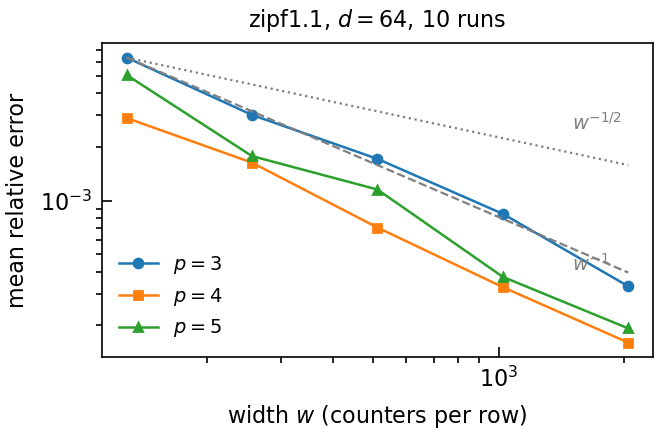

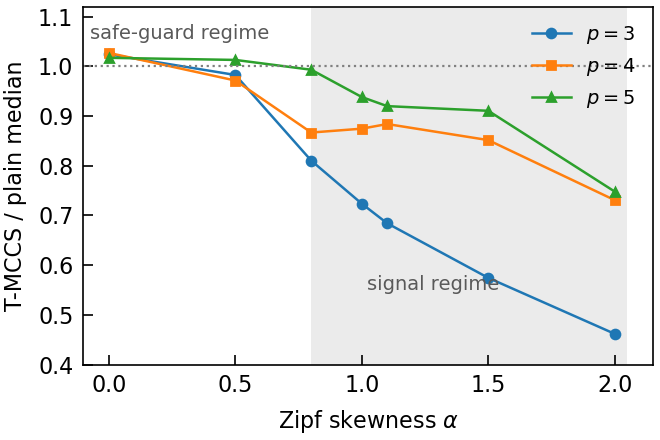

In [3]:
figs.main()   # plot from the bundled archives (fast path)
from IPython.display import Image, display
for name in ("fig_sweep", "fig_regime"):
    display(Image(filename=os.path.join(ART, "tables", "figs_out",
                                        name + ".png")))


## 总结 — 对账清单

| 对象 | 协议 | 结果 |
|---|---|---|
| Table 2 | 5 轮，7 数据集 × p=3,4,5 | 42/42 CCS 格命中论文值；AMS 列不可复现（random_device，论文侧） |
| Table 3 | 1000 runs × 21 配置 | 83/84 逐位一致；Fixed20(p=3,α=1.0) 疑论文转录笔误 |
| Table 4 | T=100 × 6 组合 | 修复共轭 bug 后全列命中（归档 + 论文） |
| Table 5 | T=24 | 3-star + CS 列逐位一致；CCS 列为已知取数缺口（已标注） |
| 图 1/2 | 重算 15+36 项 | 3 位有效数字全部命中归档 |

**为什么可以相信**：每个脚本都是原始生产者的忠实移植（RNG 抽取顺序、种子
基准、协议参数逐一保持），论文值、归档日志、复现值三方对账；归档日志随包
分发（`../results/`）可独立复核。正文其余 16 个实验的复现与对账见
`../experiments/`（`run_all.py --list`）。
